# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

## Q-Learning for Home Battery Scheduling
### Reinforcement Learning

**Goal:** Learn when to charge and discharge a home battery to reduce the electricity bill for one simulated day.

1. Represent the current time slot and battery charge as a state.
2. Define the electricity cost of each action and initialize a Q-table.
3. Train a Q-learning agent over repeated simulated days.
4. Visualize training and inspect the learned battery schedule.
5. Compare the learned schedule with grid-only use and the cheapest feasible schedule.

* The home uses 1 kWh in each of six time slots.
* Grid prices change across the day. The battery can store up to 2 kWh.
* The example assumes a lossless battery, no electricity exports, and the same prices each day.

## 1. Install the required libraries

Run this cell if NumPy, pandas, or Matplotlib is missing from your notebook environment. You can skip it if all three are already installed.

In [1]:
%pip -q install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries

* NumPy stores the Q-table and samples actions.
* pandas displays the prices, Q-values, and schedules as labeled tables.
* Matplotlib plots the training results. The seed makes the training run reproducible.

In [2]:
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

seed = 42

## 3. Define the battery environment

* **State** $(t,b)$ gives the current time slot $t$ and the energy $b$ stored in the battery, in kWh. The code indexes time slots from 0. The tables display them from 1.
* **Action** is the change in stored energy. Discharge by 1 kWh, keep the battery idle, or charge by 1 kWh.
* The battery starts empty each day. It can discharge only when it holds at least 1 kWh and charge only when there is space.
* **Reward** is the negative of the current electricity cost. The agent gets a higher reward when it pays less.
* The episode ends after the sixth slot. Energy left in the battery at the end has no value in this example.

| Battery action | Battery change | Electricity bought from the grid |
| --- | ---: | ---: |
| Discharge | −1 kWh | 0 kWh |
| Idle | 0 kWh | 1 kWh |
| Charge | +1 kWh | 2 kWh |

For example, charging during slot 1 adds 1 kWh to the battery and costs 2 units. The grid supplies 1 kWh for the home and 1 kWh for the battery.

In [4]:
prices = np.array([1, 2, 6, 5, 2, 7])
n_slots = len(prices)
capacity = 2
initial_charge = 0
demand = 1  # kWh per slot

action_names = ["Discharge", "Idle", "Charge"]
charge_changes = [-1, 0, 1]

price_table = pd.DataFrame({
    "Time slot": range(1, n_slots + 1),
    "Price (units/kWh)": prices,
}).set_index("Time slot")
display(price_table)


def valid_actions(charge):
    return [
        action for action, change in enumerate(charge_changes)
        if 0 <= charge + change <= capacity]


def step(time_slot, charge, action):
    change = charge_changes[action]
    next_charge = charge + change
    grid_energy = demand + change
    cost = prices[time_slot] * grid_energy
    done = time_slot == n_slots - 1
    return next_charge, -cost, done

,Price (units/kWh)
Time slot,
1,1
2,2
3,6
4,5
5,2
6,7


## 4. Build the reward table and initialize the Q-table

* The first table shows the immediate reward for each action at each price. Whether an action is feasible also depends on the battery charge.
* The Q-table has one row for each combination of time slot and battery charge. Each entry estimates the total reward from that action through the end of the day if the agent follows its best decisions afterward.
* Feasible actions start at 0. A dash marks an action outside the battery limits.
* Some time and charge combinations cannot occur from an empty battery at the start of the day. The table includes every combination so the code can use the time and charge directly as array indices.

In [6]:
reward_table = pd.DataFrame(
    -prices[:, None] * (demand + np.array(charge_changes)),
    index=price_table.index,
    columns=action_names)

initial_q_table = np.full((n_slots, capacity + 1, len(action_names)), np.nan)
for charge in range(capacity + 1):
    initial_q_table[:, charge, valid_actions(charge)] = 0.0

state_index = pd.MultiIndex.from_product(
    [range(1, n_slots + 1), range(capacity + 1)],
    names=["Time slot", "Stored energy (kWh)"])

print("Immediate rewards by time slot")
display(reward_table)

print("Initial Q-table")
display(pd.DataFrame(
    initial_q_table.reshape(-1, len(action_names)),
    index=state_index,
    columns=action_names).fillna("—"))

Immediate rewards by time slot


,Discharge,Idle,Charge
Time slot,,,
1,0,-1,-2
2,0,-2,-4
3,0,-6,-12
4,0,-5,-10
5,0,-2,-4
6,0,-7,-14


Initial Q-table


Discharge  Idle Charge
Time slot Stored energy (kWh)                       
1         0                           —   0.0    0.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —
2         0                           —   0.0    0.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —
3         0                           —   0.0    0.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —
4         0                           —   0.0    0.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —
5         0                           —   0.0    0.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —
6         0                           —   0.0    0.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —

## 5. Select an action and update its Q-value

**Epsilon-greedy action selection**

* With probability $\varepsilon$, explore by choosing a random feasible action.
* With probability $1-\varepsilon$, exploit by choosing the feasible action with the highest Q-value. Break ties randomly during training.

**Q-learning update**

$$
Q(s,a) \leftarrow Q(s,a) + \alpha\left[\text{target} - Q(s,a)\right]
$$

* Before the final slot, the target is $r + \gamma\max_{a'}Q(s',a')$. The next state $s'$ contains the next time slot and the updated battery charge.
* In the final slot, the target is the immediate reward $r$ because the day is over.
* The learning rate $\alpha$ controls how far each update moves the estimate toward the target.
* We use $\gamma=1$ because the episode has a fixed end and every slot's cost counts equally in the daily bill.

For example, buying 1 kWh at a price of 7 in the final slot gives a target of $-7$. With $\alpha=0.2$, an initial Q-value of 0 becomes $-1.4$.

In [7]:
def choose_action(q_values, charge, epsilon, rng):
    actions = np.array(valid_actions(charge))

    # Explore by sampling a feasible action.
    if rng.random() < epsilon:
        return int(rng.choice(actions))

    # Exploit the highest Q-value and break ties randomly.
    action_values = q_values[actions]
    best_actions = actions[action_values == action_values.max()]
    return int(rng.choice(best_actions))


def update_q_value(q_table, time_slot, charge, action, reward, next_charge, done):
    target = reward

    # Future rewards count only while the day continues.
    if not done:
        next_actions = valid_actions(next_charge)
        best_next_q = q_table[time_slot + 1, next_charge, next_actions].max()
        target += discount_factor * best_next_q

    current_q = q_table[time_slot, charge, action]
    q_table[time_slot, charge, action] += learning_rate * (target - current_q)

## 6. Train the agent and inspect the learned Q-table

* Each episode simulates one day, starting with an empty battery.
* At each time slot, the agent chooses an action, observes the reward and next charge, and updates one Q-value.
* The exploration rate decreases during training. A small amount of exploration continues so the agent keeps trying other feasible actions.
* Since the rewards are negative costs, the largest Q-value corresponds to the lowest estimated cost. An unvisited feasible entry still shows its initial value of 0.

In [9]:
learning_rate = 0.2
discount_factor = 1.0
n_episodes = 3000
epsilon_start = 1.0
epsilon_end = 0.05

rng = np.random.default_rng(seed)
q_table = initial_q_table.copy()
daily_costs = []

for epsilon in np.linspace(epsilon_start, epsilon_end, n_episodes):
    charge = initial_charge
    daily_cost = 0

    for time_slot in range(n_slots):
        action = choose_action(q_table[time_slot, charge], charge, epsilon, rng)
        next_charge, reward, done = step(time_slot, charge, action)
        update_q_value(q_table, time_slot, charge, action, reward, next_charge, done)
        daily_cost -= reward
        charge = next_charge

    daily_costs.append(daily_cost)

print("Training episodes:", n_episodes)
print("Learned Q-table")
display(pd.DataFrame(
    q_table.reshape(-1, len(action_names)),
    index=state_index,
    columns=action_names).round(2).fillna("—"))

Training episodes: 3000
Learned Q-table


Discharge  Idle Charge
Time slot Stored energy (kWh)                       
1         0                           — -14.0  -10.0
          1                         0.0   0.0    0.0
          2                         0.0   0.0      —
2         0                           — -17.0  -13.0
          1                       -15.0 -11.0   -8.0
          2                         0.0   0.0      —
3         0                           — -15.0  -16.0
          1                        -9.0 -10.0  -14.0
          2                        -4.0  -8.0      —
4         0                           —  -9.0  -12.0
          1                        -4.0  -7.0  -10.0
          2                        -2.0  -5.0      —
5         0                           —  -9.0   -4.0
          1                        -7.0  -2.0   -4.0
          2                         0.0  -2.0      —
6         0                           —  -7.0  -14.0
          1                         0.0  -7.0  -14.0
          2                         0.0  -7.0      —

## 7. Visualize the training cost

* Plot the average bill over the most recent 100 training episodes to see the trend.
* The dashed line shows the bill if the home buys all its electricity directly from the grid.
* Training includes exploration, so its average bill can differ from the bill for a day when the agent always follows the learned policy.

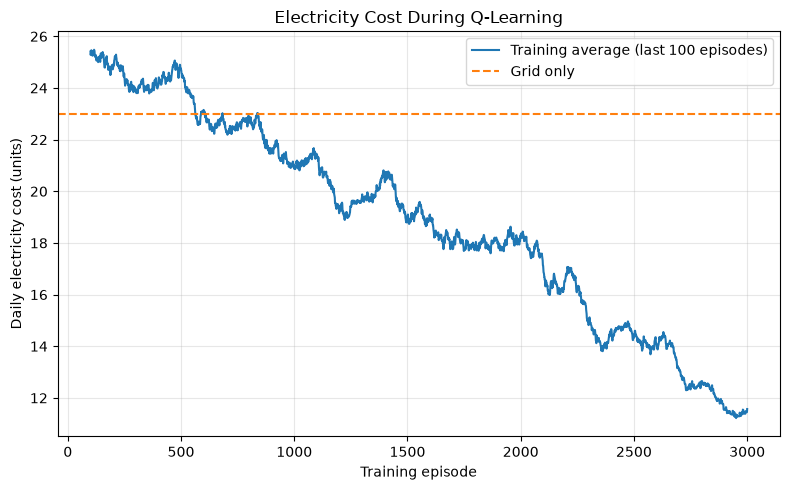

In [10]:
grid_only_cost = demand * prices.sum()
episodes = np.arange(1, n_episodes + 1)
window = min(100, n_episodes)
rolling_costs = pd.Series(daily_costs).rolling(window).mean()

plt.figure(figsize=(8, 5))
plt.plot(episodes, rolling_costs, label=f"Training average (last {window} episodes)")
plt.axhline(grid_only_cost, color="tab:orange", linestyle="--", label="Grid only")
plt.xlabel("Training episode")
plt.ylabel("Daily electricity cost (units)")
plt.title("Electricity Cost During Q-Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Follow the learned policy

* Simulate one more day. At each slot, choose the feasible action with the highest Q-value.
* The table shows when the battery charges or discharges, how much energy remains, and how much the household pays.
* Check the low-price and high-price slots. When does the learned policy buy extra electricity? When does it use stored energy?

In [11]:
charge = initial_charge
schedule = []

for time_slot, price in enumerate(prices):
    actions = valid_actions(charge)
    action = actions[np.argmax(q_table[time_slot, charge, actions])]
    next_charge, reward, _ = step(time_slot, charge, action)

    schedule.append({
        "Time slot": time_slot + 1,
        "Price (units/kWh)": price,
        "Battery before (kWh)": charge,
        "Action": action_names[action],
        "Grid purchase (kWh)": demand + charge_changes[action],
        "Battery after (kWh)": next_charge,
        "Cost (units)": -reward,
    })
    charge = next_charge

schedule_table = pd.DataFrame(schedule).set_index("Time slot")
learned_cost = schedule_table["Cost (units)"].sum()

display(schedule_table)
print(f"Daily cost under the learned policy: {learned_cost} units")

,Price (units/kWh),Battery before (kWh),Action,Grid purchase (kWh),Battery after (kWh),Cost (units)
Time slot,,,,,,
1,1,0,Charge,2,1,2
2,2,1,Charge,2,2,4
3,6,2,Discharge,0,1,0
4,5,1,Discharge,0,0,0
5,2,0,Charge,2,1,4
6,7,1,Discharge,0,0,0


Daily cost under the learned policy: 10 units


## 9. Compare the learned schedule with two benchmarks

* **Grid only** keeps the battery idle throughout the day.
* **Cheapest feasible schedule** comes from checking every possible action sequence and discarding those that violate the battery limits. With three actions and six slots, there are only $3^6=729$ sequences to check.
* If the learned policy has the same cost as the cheapest feasible schedule, it found an optimal schedule for this simulated day.

In [12]:
lowest_cost = grid_only_cost

for action_sequence in product(range(len(action_names)), repeat=n_slots):
    charge = initial_charge
    total_cost = 0

    for time_slot, action in enumerate(action_sequence):
        if action not in valid_actions(charge):
            break

        charge, reward, _ = step(time_slot, charge, action)
        total_cost -= reward
    else:
        # This runs only when every action in the sequence was feasible.
        lowest_cost = min(lowest_cost, total_cost)

comparison = pd.DataFrame({
    "Schedule": ["Grid only", "Learned policy", "Cheapest feasible schedule"],
    "Daily cost (units)": [grid_only_cost, learned_cost, lowest_cost],
}).set_index("Schedule")

display(comparison)
print(f"Savings relative to grid only: {grid_only_cost - learned_cost} units")
print(f"Cost above the cheapest schedule: {learned_cost - lowest_cost} units")

,Daily cost (units)
Schedule,
Grid only,23
Learned policy,10
Cheapest feasible schedule,10


Savings relative to grid only: 13 units
Cost above the cheapest schedule: 0 units
